# Multivariate Analysis Of IMDb Dataset


## Objective

- The objective of this notebook is to perform multivariate analysis on the cleaned IMDb dataset to examine the combined relationship among three or more variables.
- The analysis aims to identify patterns, trends, and interactions between movie characteristics such as genre, certificate, year, rating, runtime, vote count, and metascore using appropriate statistical summaries and visualizations.

## Loading the Cleaned Dataset

The cleaned IMDb dataset was imported for exploratory data analysis and multivariate analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
cleaned_data = pd.read_csv("clean_dataset_final.csv")

In [4]:
cleaned_data

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,"['thriller', 'drama', 'crime']",2026,4.5,94.0,TV-MA,NaN,1.3
1,28 Years Later: The Bone Temple,"['thriller', 'sci-fi']",2026,7.3,109.0,R,81.0,88.0
2,3 Body Problem,['fantasy'],2024,7.5,NaN,TV-MA,NaN,180.0
3,56 Days,['romance'],2026,6.7,NaN,TV-MA,NaN,9.6
4,A Big Bold Beautiful Journey,['romance'],2025,6.0,109.0,R,43.0,21.0
...,...,...,...,...,...,...,...,...
250,Young Sherlock,"['action', 'adventure']",2026,7.5,NaN,TV-14,NaN,26.0
251,Your Friends & Neighbors,"['drama', 'crime']",2025,7.7,NaN,TV-MA,NaN,53.0
252,Youth,['romance'],2026,7.1,140.0,Unknown,NaN,6.5
253,Zootopia,['animation'],2016,8.0,108.0,PG,78.0,635.0


In [5]:
import ast
dfm=cleaned_data.copy()
dfm["Genre"]=dfm["Genre"].apply(ast.literal_eval)
dfm=dfm.explode("Genre")
dfm["Genre"]=dfm["Genre"].str.strip()
dfm=dfm.reset_index(drop=True)

In [6]:
dfm.head()

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,thriller,2026,4.5,94.0,TV-MA,NaN,1.3
1,180,drama,2026,4.5,94.0,TV-MA,NaN,1.3
2,180,crime,2026,4.5,94.0,TV-MA,NaN,1.3
3,28 Years Later: The Bone Temple,thriller,2026,7.3,109.0,R,81.0,88.0
4,28 Years Later: The Bone Temple,sci-fi,2026,7.3,109.0,R,81.0,88.0


In [7]:
dfm.describe(include="all")

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
count,495,495,495.000000,440.000000,212.000000,495,166.000000,440.000000
unique,255,10,NaN,NaN,NaN,9,NaN,NaN
top,Invincible,thriller,NaN,NaN,NaN,TV-MA,NaN,NaN
freq,7,50,NaN,NaN,NaN,159,NaN,NaN
mean,NaN,NaN,2020.331313,7.590682,124.235849,NaN,63.120482,306.723605
std,NaN,NaN,8.512632,1.084654,31.447105,NaN,15.914847,510.937997
min,NaN,NaN,1972.000000,4.500000,81.000000,NaN,33.000000,0.562000
25%,NaN,NaN,2018.000000,6.900000,104.000000,NaN,53.000000,27.000000
50%,NaN,NaN,2025.000000,7.800000,114.000000,NaN,64.000000,128.000000
75%,NaN,NaN,2026.000000,8.400000,140.000000,NaN,73.000000,331.000000


## Column Classification

The dataset variables were classified into categorical, numerical, and time-based variables to facilitate appropriate exploratory data analysis techniques.

**Categorical Variables**

- Title (Movie title/identifier)
- Genre
- Certificate

**Numerical Variables**

- Rating
- Runtime (minutes)
- Metascore
- Votes_K (vote count in thousands)

**Time-Based Variable**

- Year


## Multivariate Analysis Structure

Multivariate analysis was performed to examine the relationships among three or more variables simultaneously and to identify patterns that cannot be observed through univariate or bivariate analysis alone.

1. Non-Visual Analysis
- Grouped aggregation using multiple variables
- Multi-level pivot tables
- Summary statistics across variable combinations

2. Visual Analysis
- Grouped bar plots
- Heatmaps
- Pair plots
- Faceted plots (where applicable)
- Scatter plots with multiple encodings (e.g., hue, size, or style)


## Non Visual Analysis

### Genre,Certificate,Rating

In [8]:
pd.set_option("display.max_rows", None)
dfm.groupby(["Genre","Certificate"])["Rating"].mean()

Genre      Certificate
action     PG             7.050000
           PG-13          6.366667
           R              6.536364
           TV-14          7.585714
           TV-MA          8.375000
           TV-PG          8.500000
           TV-Y7-FV       9.300000
           Unknown        8.400000
adventure  PG             6.980000
           PG-13          7.610000
           R              6.733333
           TV-14          7.780000
           TV-MA          8.563636
           TV-PG          8.000000
           TV-Y7-FV       9.300000
           Unknown        8.300000
animation  G              7.700000
           PG             7.533333
           PG-13          7.400000
           R              8.000000
           TV-14          8.370000
           TV-MA          8.607143
           TV-PG          8.540000
           TV-Y7-FV       9.300000
           Unknown             NaN
comedy     PG             6.980000
           PG-13          6.920000
           R              6.1666

In [ ]:
pd.pivot_table(data=dfb,index="Certificate",columns="Genre",values="Rating", aggfunc="mean")

**Analysis: Average IMDb Rating by Genre and Certificate**

The average IMDb rating was calculated for each Genre–Certificate combination to understand how audience ratings vary across different content categories and certification types.

**Observations**

1. **TV-MA certified titles generally receive higher ratings across most genres.** For example, Adventure (8.56), Animation (8.61), Fantasy (8.34), and Sci-fi (8.30) show strong average ratings under the TV-MA category.
2. **R-rated titles tend to have comparatively lower average ratings.** Across most genres, the average ratings for R-certified titles range between 6.1 and 6.7, which is lower than the corresponding TV-14 and TV-MA ratings.
3. **Animation is one of the highest-rated genres regardless of certification.** Animation titles consistently achieve strong ratings across TV-14 (8.37), TV-MA (8.61), and TV-PG (8.54) categories.
4. **Fantasy, Adventure, and Sci-fi genres also demonstrate strong audience reception.** These genres maintain ratings above 7.5 across several certification categories.
5. **Comedy shows relatively lower average ratings compared to other genres.** Its ratings remain below 7.0 in the PG, PG-13, and R categories.
6. **TV-14 titles generally perform better than PG-13 and R-rated titles.** Most TV-14 Genre–Certificate combinations have ratings above 7.5, indicating favorable audience reception.
7. **TV-Y7-FV combinations show exceptionally high ratings (9.3).** However, these values may be based on a very small number of observations and should therefore be interpreted cautiously.

**Conclusion**

>The analysis indicates that audience ratings are influenced by both genre and certification.
>TV-MA and TV-14 certified titles generally receive higher ratings, while R-rated titles tend to receive lower ratings.
> Among genres, Animation, Adventure, Fantasy, and Sci-fi consistently perform well across multiple certification categories. These findings suggest that both content type and target audience classification play an important role in shaping audience perception and ratings.
The analysis is based on mean ratings only. Some Genre–Certificate combinations may contain a limited number of titles; therefore, results should be interpreted together with the corresponding observation counts.


**Observations**
- TV-MA certified titles consistently receive high ratings across most genres, with ratings above 8.0 in Action, Adventure, Animation, Crime, Drama, Fantasy, and Sci-Fi.
- Animation appears to be one of the highest-rated genres across multiple certificate categories. For example:
- R-rated titles generally have lower average ratings (mostly between 6.1 and 6.8) compared to TV-MA and TV-PG titles.
- TV-PG titles show consistently high ratings across genres, with most averages exceeding 8.0.
- Adventure and Fantasy genres maintain relatively high ratings across several certificate categories.
- Comedy tends to have lower average ratings than many other genres regardless of certificate category.
- The highest average rating in the table is 9.3, observed for TV-Y7-FV titles. However, this category contains very few observations and should be interpreted cautiously.
- Several cells contain NaN, indicating that no titles exist in that Genre–Certificate combination.

**Limitation**
- Some Genre–Certificate combinations contain very few titles.
-  Therefore, extremely high or low average ratings may be influenced by small sample sizes and may not represent broader audience preferences.

**Conclusion**

The pivot table suggests that TV-MA and TV-PG certified titles generally achieve higher average IMDb ratings across multiple genres. Animation, Adventure, and Fantasy emerge as some of the most highly rated genres, whereas Comedy and several R-rated genre combinations tend to have comparatively lower average ratings. However, results for categories with very few observations should be interpreted cautiously.

### Genre,Certificate,Votes_K

In [12]:
pd.pivot_table(
    data=dfm,
    index="Genre",
    columns="Certificate",
    values="Votes_K",
    aggfunc=["mean", "count"]
)

mean                                                           \
Certificate      G      PG        PG-13           R       TV-14       TV-MA   
Genre                                                                         
action         NaN   72.00    92.333333  127.672727  115.357143  486.750000   
adventure      NaN  102.80   988.400000   71.000000  204.400000  615.727273   
animation    738.5  320.25   384.500000  226.000000  233.410000  257.498929   
comedy         NaN  102.80   214.020000   49.102333  167.800000  160.508333   
crime          NaN  128.00   147.500000  327.033333   86.100000  461.413636   
drama          NaN     NaN    31.233333  160.985714  127.512500  417.777778   
fantasy        NaN  283.80   698.666667  183.000000  399.428571  548.142857   
romance        NaN  486.00   508.380000  186.375000  394.250000  202.308333   
sci-fi         NaN   36.00  1033.625000  104.625000  312.333333  429.388889   
thriller       NaN     NaN    73.500000   99.716667  215.600000  399.800000   

                                             count                          \
Certificate       TV-PG TV-Y7-FV     Unknown     G    PG PG-13     R TV-14   
Genre                                                                        
action         6.400000    440.0   92.500000   NaN   2.0   3.0  11.0   7.0   
adventure     79.700000    440.0  137.000000   NaN   5.0  10.0   3.0   5.0   
animation     76.960000    440.0         NaN   2.0  12.0   2.0   1.0  10.0   
comedy       159.000000      NaN    6.637000   NaN   5.0   5.0  12.0   7.0   
crime          6.400000      NaN   92.500000   NaN   1.0   2.0   9.0  12.0   
drama        159.000000      NaN    7.900000   NaN   NaN   3.0   7.0   8.0   
fantasy       31.000000    440.0         NaN   NaN   5.0   6.0   3.0   7.0   
romance      573.333333      NaN    8.180429   NaN   1.0  10.0   8.0   8.0   
sci-fi        79.700000      NaN         NaN   NaN   1.0   8.0   8.0   3.0   
thriller            NaN      NaN   47.840500   NaN   NaN   2.0  18.0   6.0   

                                          
Certificate TV-MA TV-PG TV-Y7-FV Unknown  
Genre                                     
action       12.0   1.0      1.0     2.0  
adventure    11.0   2.0      1.0     1.0  
animation    14.0   5.0      1.0     0.0  
comedy       12.0   1.0      NaN     4.0  
crime        22.0   1.0      NaN     2.0  
drama        27.0   1.0      NaN     1.0  
fantasy      14.0   2.0      1.0     0.0  
romance      12.0   3.0      NaN     7.0  
sci-fi       18.0   2.0      NaN     0.0  
thriller     17.0   NaN      NaN     4.0

**Observations**

1. Audience engagement varies considerably across different **Genre–Certificate** combinations.
2. **TV-MA** certified titles generally receive high average vote counts across several genres, particularly **Adventure (615.73K)**, **Fantasy (548.14K)**, **Action (486.75K)**, and **Crime (461.41K)**. These averages are supported by relatively larger sample sizes (11–22 titles), making them more reliable.
3. **Sci-fi (PG-13)** and **Adventure (PG-13)** record the highest average vote counts (**1033.63K** and **988.40K**, respectively). However, these results are based on **8** and **10** titles and may be influenced by a few highly popular movies.
4. **Fantasy** and **Romance** also show strong audience engagement, especially under the **PG-13**, **TV-MA**, and **TV-PG** certificate categories.
5. **Animation** demonstrates consistently good audience engagement across multiple certificate categories, particularly **TV-MA**, where the average is based on **14 titles**.
6. **Comedy** generally has lower average vote counts across most certificate categories, indicating comparatively lower audience engagement than genres such as Adventure, Sci-fi, Fantasy, and Crime.
7. Several Genre–Certificate combinations, such as **G**, **TV-Y7-FV**, and some **PG** categories, contain only **1–2 titles**. Therefore, their average vote counts should be interpreted cautiously, as they may not represent the overall trend.

**Conclusion**
>The analysis suggests that audience engagement is influenced by both **genre** and **certificate**. **Adventure, Sci-fi, Fantasy, Crime, and Action**, particularly under **TV-MA** and **PG-13** certifications, tend to attract higher audience participation. Since some combinations have very small sample sizes, both the **mean vote count** and the **number of titles** should be considered when interpreting the results.The **count** represents the number of titles in each Genre–Certificate combination, **not the number of audience votes**. Combinations with larger counts provide more reliable average vote counts, whereas results based on only one or two titles may be influenced by individual highly popular movies and should be interpreted with caution.



### Genre,Rating,Runtime

In [13]:
dfm.groupby(["Genre"])[["Rating","Runtime"]].mean()

,Rating,Runtime
Genre,,
action,7.520513,127.608696
adventure,7.839474,131.826087
animation,8.187234,115.850000
comedy,7.021739,110.307692
crime,7.646939,132.333333
drama,7.610638,119.428571
fantasy,7.934211,128.888889
romance,7.373469,126.375000
sci-fi,7.790000,131.428571


**Observations**

1. **Animation has the highest average rating (8.19)** despite having one of the shortest average runtimes (115.85 minutes), indicating strong audience appreciation regardless of duration.
2. **Fantasy (7.93), Adventure (7.84), and Sci-fi (7.79)** are among the highest-rated genres and also have relatively long average runtimes (approximately 129–132 minutes).
3. **Crime (132.33 minutes)** has the longest average runtime among all genres and maintains a relatively strong average rating of 7.65.
4. **Comedy has the lowest average rating (7.02)** and also the shortest average runtime (110.31 minutes), suggesting comparatively lower audience reception.
5. **Thriller (7.11)** and **Romance (7.37)** receive moderate ratings despite having average runtimes above 120 minutes.
6. Genres such as **Adventure, Crime, Fantasy, and Sci-fi** combine both longer runtimes and higher ratings, indicating that audiences may respond positively to more detailed storytelling in these genres.
7. There is a slight positive association between runtime and rating, although exceptions such as Animation demonstrate that longer runtime is not always necessary for achieving high ratings.

**Conclusion**
>The analysis suggests that genres with longer average runtimes, such as Adventure, Crime, Fantasy, and Sci-fi, generally receive favorable audience ratings. However, Animation achieves the highest average rating despite a comparatively shorter runtime, indicating that content quality and genre characteristics may be more influential than duration alone. Overall, runtime appears to have a moderate influence on audience ratings, but it is not the sole determinant of a title's success.


### Genre,Rating,Metascore

In [14]:
pd.pivot_table(data=dfm,index="Genre",values=["Rating","Metascore"],aggfunc="mean")

,Metascore,Rating
Genre,,
action,61.187500,7.520513
adventure,65.277778,7.839474
animation,69.388889,8.187234
comedy,59.090909,7.021739
crime,65.333333,7.646939
drama,60.300000,7.610638
fantasy,60.769231,7.934211
romance,61.350000,7.373469
sci-fi,66.764706,7.790000


**Observations**

1. **Animation records the highest average Rating (8.19) and the highest average Metascore (69.39)**, indicating strong appreciation from both audiences and critics.
2. **Sci-fi (Rating: 7.79, Metascore: 66.76), Crime (Rating: 7.65, Metascore: 65.33), and Adventure (Rating: 7.84, Metascore: 65.28)** also perform well in both audience and critic evaluations.
3. **Comedy has the lowest average Rating (7.02) and one of the lowest average Metascores (59.09)**, suggesting comparatively weaker reception from both audiences and critics.
4. **Drama receives a relatively good audience rating (7.61) despite having a moderate Metascore (60.30)**, indicating that audiences may view Drama titles more favorably than critics.
5. **Fantasy achieves a high average Rating (7.93) while maintaining a moderate Metascore (60.77)**, suggesting stronger audience appreciation compared to critic reviews.
6. Across most genres, higher Metascores are generally associated with higher IMDb Ratings, indicating a positive relationship between critic and audience evaluations.
7. The difference between Rating and Metascore varies across genres, highlighting that critic opinions and audience preferences do not always align perfectly.

**Conclusion**
>The analysis suggests that genres receiving strong critic reviews generally also receive favorable audience ratings. Animation, Sci-fi, Adventure, and Crime emerge as the best-performing genres in terms of both audience and critic reception. However, genres such as Fantasy and Drama demonstrate that audience preferences can sometimes differ from critic evaluations. Overall, a positive relationship exists between Metascore and IMDb Rating across genres.


### Genre,Rating,Votes_K

In [15]:
dfm.groupby(["Genre"])[["Rating","Votes_K"]].mean()

,Rating,Votes_K
Genre,,
action,7.520513,233.469231
adventure,7.839474,503.747368
animation,8.187234,278.274149
comedy,7.021739,118.686435
crime,7.646939,300.857143
drama,7.610638,291.225532
fantasy,7.934211,450.842105
romance,7.373469,294.280878
sci-fi,7.790000,449.185000


**Observations**

1. **Animation has the highest average IMDb Rating (8.19)**, indicating strong audience appreciation. However, it does not have the highest average vote count, suggesting that highly rated content does not always receive the largest audience engagement.
2. **Adventure records both a high average Rating (7.84) and the highest average Votes (503.75K)**, making it one of the most successful genres in terms of both audience reception and popularity.
3. **Fantasy (7.93, 450.84K votes) and Sci-fi (7.79, 449.19K votes)** also perform strongly, demonstrating both high ratings and substantial audience engagement.
4. **Comedy has the lowest average Rating (7.02) and the lowest average Votes (118.69K)**, indicating comparatively lower audience interest and reception.
5. **Crime and Drama maintain relatively strong ratings (7.65 and 7.61 respectively) along with moderate audience engagement**, suggesting consistent popularity among viewers.
6. **Action receives a moderate Rating (7.52) but relatively lower average Votes (233.47K)** compared to Adventure, Fantasy, and Sci-fi.
7. Genres with higher ratings generally tend to attract more votes, although exceptions such as Animation indicate that audience appreciation and audience size are not always directly proportional.

**Conclusion**
>The analysis suggests a positive relationship between audience ratings and audience engagement. Adventure, Fantasy, and Sci-fi emerge as the strongest-performing genres, combining high ratings with substantial viewer participation. Animation achieves the highest rating but comparatively lower vote counts, indicating strong audience satisfaction among a smaller viewer base. In contrast, Comedy shows both lower ratings and lower engagement. Overall, genres that are well received by audiences tend to attract greater participation and popularity.


In [ ]:
# pd.pivot_table(data=dfm,index="Year",columns="Genre",values="Votes_K",aggfunc="mean")

### Rating,Runtime,Metascore,Votes_K

In [16]:
dfm[["Rating","Runtime","Metascore","Votes_K"]].corr()

,Rating,Runtime,Metascore,Votes_K
Rating,1.000000,0.567417,0.745234,0.474254
Runtime,0.567417,1.000000,0.453446,0.328339
Metascore,0.745234,0.453446,1.000000,0.430100
Votes_K,0.474254,0.328339,0.430100,1.000000


**Observations**

1. **Rating and Metascore show the strongest positive correlation (0.745).**
   * This indicates that titles receiving higher critic scores generally tend to receive higher audience ratings as well.
2. **Rating and Runtime exhibit a moderate positive correlation (0.567).**
   * Longer titles tend to receive better audience ratings, although the relationship is not very strong.
3. **Rating and Votes_K show a moderate positive correlation (0.474).**
   * Highly rated titles generally attract more audience engagement, reflected by higher vote counts.
4. **Metascore and Runtime have a moderate positive correlation (0.453).**
   * Titles with longer runtimes tend to receive slightly better critic evaluations.
5. **Metascore and Votes_K show a moderate positive correlation (0.430).**
   * Critically acclaimed titles often receive greater audience attention.
6. **Runtime and Votes_K have the weakest positive correlation (0.328).**
   * Runtime alone does not strongly influence audience engagement.
7. All correlations are positive, indicating that improvements in one performance metric are generally associated with improvements in the others.

**Conclusion**
>The correlation analysis reveals that **Metascore has the strongest relationship with IMDb Rating**, suggesting a considerable degree of agreement between critics and audiences. Audience engagement (Votes_K) also increases with both Rating and Metascore, although the relationships are moderate. Runtime demonstrates a positive but weaker association with Ratings, indicating that longer content may contribute to audience appreciation but is not the primary factor driving success.
Critic reviews (Metascore) appear to be the strongest predictor of audience ratings in this dataset, while audience engagement is influenced by a combination of rating quality, critic reception, and runtime.


### Year,Genre,Rating

In [19]:
pd.pivot_table(
    dfm,
    index="Year",
    columns="Genre",
    values="Rating",
    aggfunc=["mean","count"]
)

mean                                                           \
Genre    action adventure animation comedy     crime     drama   fantasy   
Year                                                                       
1972        NaN       NaN       NaN    NaN  9.200000       NaN       NaN   
1987        NaN       NaN       NaN    NaN       NaN       NaN       NaN   
1988        NaN       NaN  8.000000    NaN       NaN       NaN       NaN   
1989        NaN       NaN  8.600000  6.100       NaN       NaN       NaN   
1994        NaN       NaN       NaN    NaN       NaN  7.900000       NaN   
1997        NaN       NaN  8.700000    NaN       NaN       NaN       NaN   
1999        NaN    7.1000  8.100000    NaN  8.650000       NaN  7.100000   
2000        NaN       NaN       NaN  8.200       NaN  8.200000       NaN   
2001        NaN    8.2000  8.600000    NaN       NaN       NaN  8.300000   
2002        NaN       NaN       NaN    NaN  9.300000       NaN       NaN   
2003   7.800000       NaN       NaN    NaN  7.800000       NaN       NaN   
2004        NaN    8.3000       NaN    NaN       NaN       NaN  8.300000   
2005   9.300000    9.3000  9.300000  9.000       NaN  8.400000  8.850000   
2006        NaN       NaN  8.100000  7.000  8.600000       NaN       NaN   
2007        NaN       NaN  8.400000    NaN       NaN       NaN       NaN   
2008        NaN       NaN  8.500000    NaN  8.850000  9.500000       NaN   
2009        NaN       NaN  9.100000    NaN       NaN       NaN  7.700000   
2010        NaN    8.8000       NaN    NaN       NaN       NaN       NaN   
2011   8.850000    9.2000  8.600000    NaN  8.600000  9.200000  9.200000   
2012        NaN       NaN  8.600000    NaN       NaN       NaN       NaN   
2013   9.100000    9.0500  9.050000    NaN  8.700000  8.700000  9.100000   
2014        NaN    8.5000  8.800000    NaN  8.800000  8.300000  8.300000   
2015        NaN    8.0000       NaN    NaN  8.800000       NaN       NaN   
2016        NaN       NaN  8.100000    NaN       NaN  8.600000  8.350000   
2017        NaN       NaN       NaN    NaN       NaN       NaN       NaN   
2018   8.000000    7.8000  8.400000  8.800  8.000000  8.300000       NaN   
2019   7.750000       NaN  8.700000  7.750  8.300000  8.300000  8.133333   
2020   8.500000    8.5000  8.500000    NaN       NaN       NaN  8.500000   
2021   8.700000    8.7000  8.850000  8.100       NaN  8.300000  7.700000   
2022   8.300000    8.3000  7.500000    NaN  7.500000  7.800000  8.450000   
2023   7.700000    7.6800  8.200000  7.920  7.900000  8.133333  8.125000   
2024        NaN    8.3000  7.700000  7.500  7.560000  7.500000  7.500000   
2025   7.200000    6.9250  7.700000  6.940  7.477778  7.625000  7.287500   
2026   6.933333    7.5375  7.166667  6.516  6.400000  6.766667  7.300000   
2027        NaN       NaN       NaN    NaN       NaN       NaN       NaN   

                                     count                                   \
Genre   romance    sci-fi  thriller action adventure animation comedy crime   
Year                                                                          
1972        NaN       NaN       NaN    NaN       NaN       NaN    NaN   1.0   
1987   8.000000       NaN       NaN    NaN       NaN       NaN    NaN   NaN   
1988        NaN       NaN       NaN    NaN       NaN       1.0    NaN   NaN   
1989        NaN       NaN       NaN    NaN       NaN       1.0    1.0   NaN   
1994   8.500000       NaN       NaN    NaN       NaN       NaN    NaN   NaN   
1997   8.200000       NaN       NaN    NaN       NaN       1.0    NaN   NaN   
1999        NaN       NaN  8.100000    NaN       1.0       1.0    NaN   2.0   
2000        NaN       NaN       NaN    NaN       NaN       NaN    1.0   NaN   
2001        NaN  7.500000       NaN    NaN       2.0       1.0    NaN   NaN   
2002        NaN       NaN       NaN    NaN       NaN       NaN    NaN   1.0   
2003   7.800000       NaN  7.800000    1.0       NaN       NaN    NaN   1.0   
2004   7.800000 

**Observations**

1. Average IMDb ratings vary across different years and genres, indicating changes in audience reception over time.
2. Animation, Adventure, and Fantasy generally maintain higher average ratings across several years, often scoring above 8.0.
3. Most 2025 and 2026 Genre–Year combinations have larger sample sizes (up to 25 titles), making their average ratings more representative than earlier years.
4. Compared with earlier years, average ratings in 2025 and 2026 are generally lower, mostly ranging between 6.3 and 7.7 across genres.
5. Many Year–Genre combinations before 2025 contain only 1–3 titles, so exceptionally high ratings (such as 9.2 or 9.5) may be influenced by a small sample size.
6. Several cells contain NaN because no titles exist for those particular Year–Genre combinations.

**Conclusion**
>The analysis indicates that average ratings differ across genres and release years. While some genres consistently achieve higher ratings, recent years (2025–2026) show comparatively lower average ratings. Since many earlier Year–Genre combinations are based on very few titles, the findings should be interpreted alongside the corresponding title counts.

## Visual Analysis

### Genre, Certificate,Rating

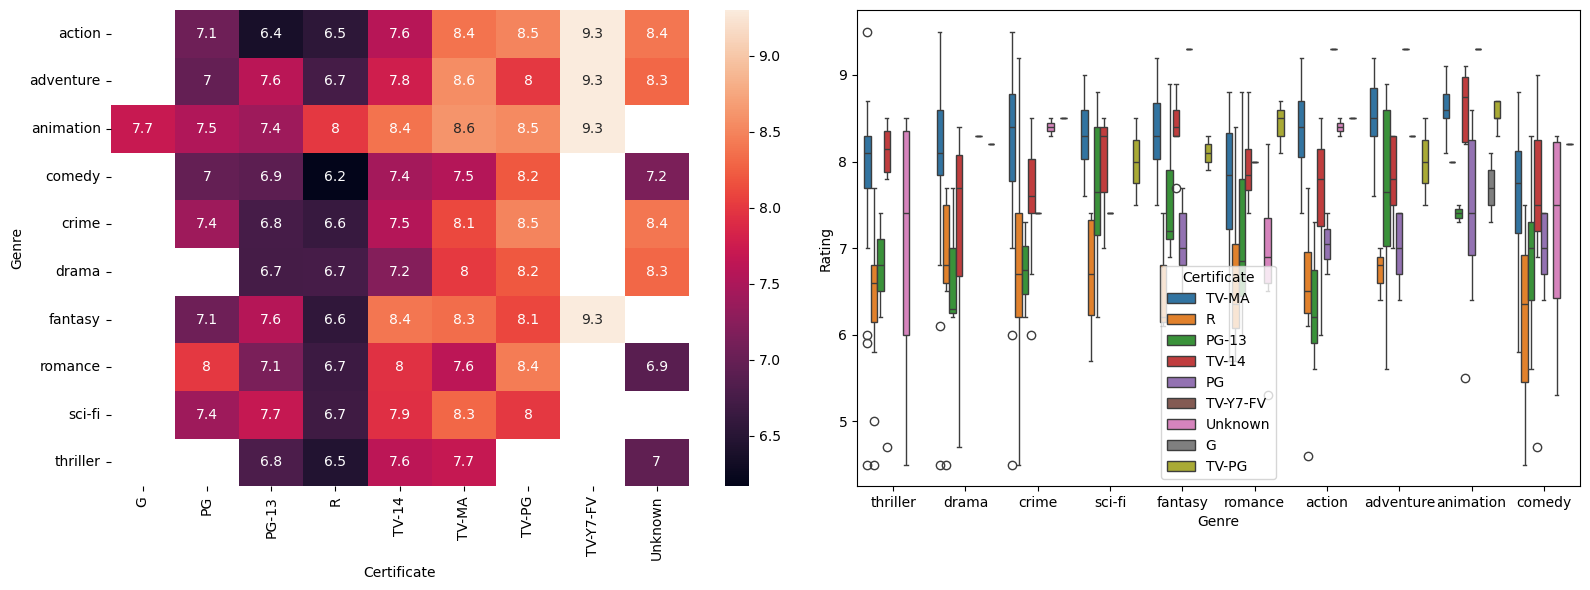

In [21]:
# Genre , Certificate , Rating
# Heatmap,catplot,FacetGrid

pivot=pd.pivot_table(data=dfm,index="Genre",columns="Certificate",values="Rating",aggfunc="mean")
fig,ax=plt.subplots(1,2,figsize=(16,6))

sns.heatmap(pivot,annot=True,ax=ax[0])
sns.boxplot(data=dfm,x="Genre",y="Rating",hue="Certificate",ax=ax[1])
plt.tight_layout()

**Insight** - How do ratings vary across genres and certificates simulatneoudly ?

1. Heatmap (Genre × Certificate × Rating)

**Observations**
- Average ratings vary across both genres and certificate categories.
- TV-MA consistently shows high ratings across most genres, generally above 8.0.
- Animation records some of the highest average ratings across multiple certificate categories.
- Adventure, Fantasy, and Sci-fi maintain strong ratings irrespective of certification.
- R-rated titles generally have lower average ratings compared to TV-14 and TV-MA titles.
- The TV-Y7-FV category shows exceptionally high ratings (9.3), though this may be due to a limited number of observations.
- The heatmap indicates that both genre and certification influence audience ratings.

**Conclusion**
>Genres such as Animation, Adventure, Fantasy, and Sci-fi perform strongly across several certification categories, while TV-MA certified titles generally receive the highest audience ratings.

2. Grouped Boxplot (Genre vs Rating by Certificate)

**Observations**
- Rating distributions vary considerably across genres and certificate categories.
- TV-MA titles generally exhibit higher median ratings than PG and R-rated titles.
- Animation, Adventure, and Fantasy show relatively high median ratings across multiple certificates.
- Several genres contain outliers, indicating the presence of exceptionally high- or low-rated titles.
- Rating variability differs across genres, suggesting differences in audience reception.
- PG and R categories generally display lower median ratings compared to TV-14 and TV-MA.

**Conclusion**
>The distribution of ratings suggests that both genre and certification influence audience perception, with TV-MA titles generally receiving stronger ratings.

### Genre, Certificate,Votes_K

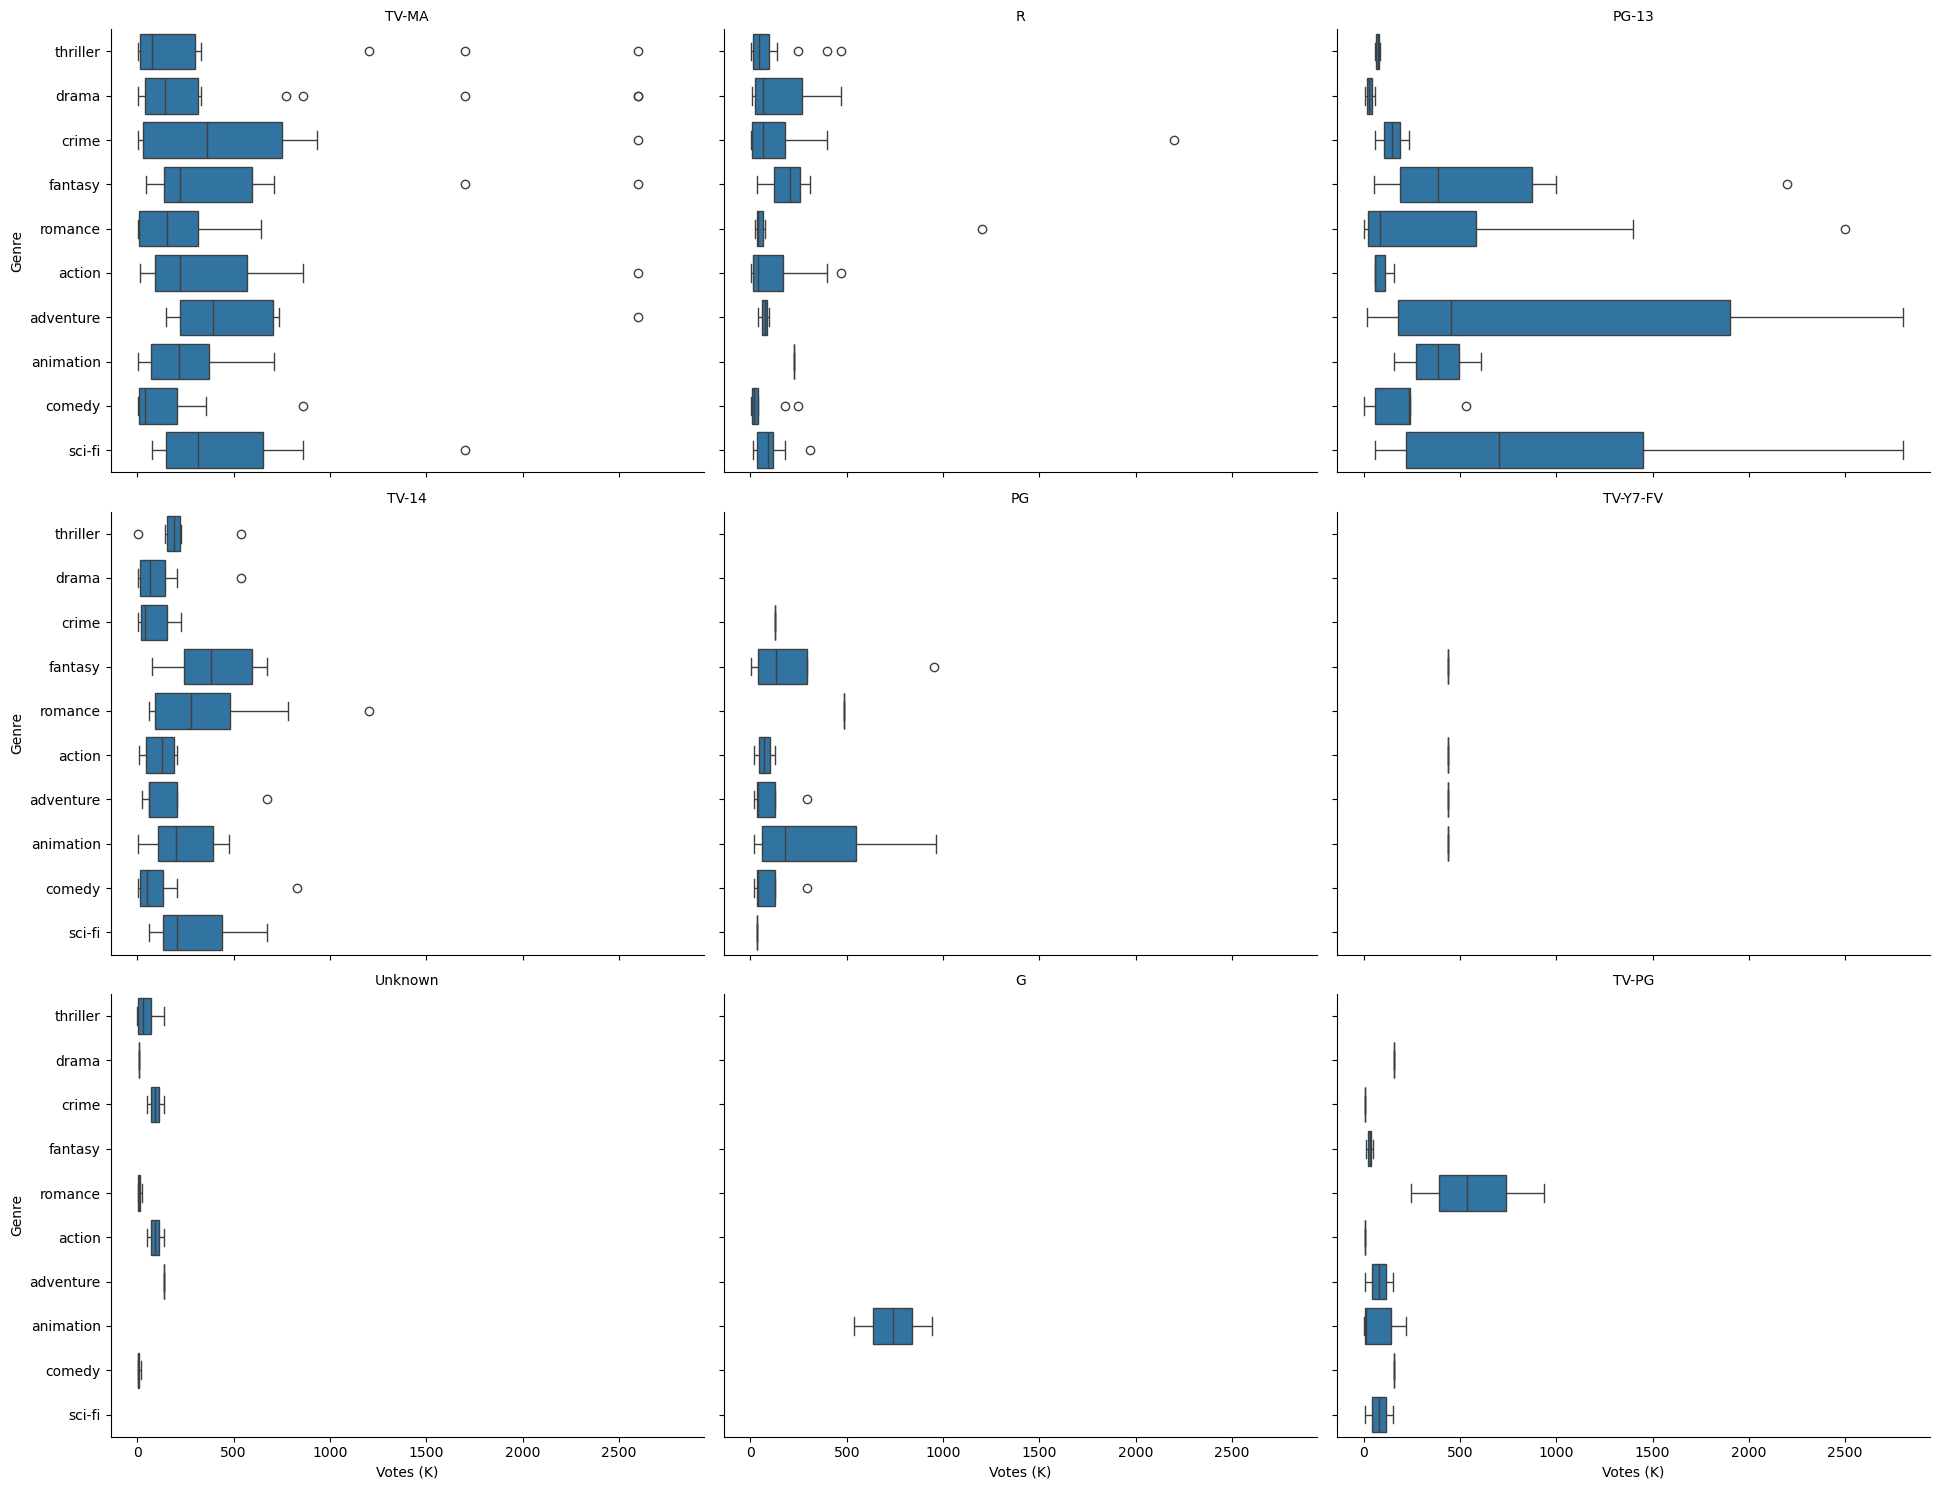

In [22]:
# Genre , Certificate , Votes

g = sns.FacetGrid(
    dfm,
    col="Certificate",
    col_wrap=3,
    height=5,
    aspect=1.3
)
g.map_dataframe(
    sns.boxplot,
    x="Votes_K",
    y="Genre"
)
g.set_titles("{col_name}")
g.set_xlabels("Votes (K)")
g.set_ylabels("Genre")
plt.tight_layout()
plt.show()

**Insights**- Which Genre Certificate combinations attract the highest audience engagemnet?

**Observations**
- Audience engagement differs considerably across Genre–Certificate combinations.
- TV-MA and PG-13 contain several high-vote titles across multiple genres.
- Animation, Adventure, Fantasy and Sci-fi display some of the highest vote counts.
- Numerous outliers indicate exceptionally popular movies.
- Several certificate categories contain very few observations.

**Conclusion**
>Audience engagement depends on both Genre and Certificate. Certain combinations consistently attract higher viewer participation, while others have only a small number of titles.

### Genre, Runtime,Rating

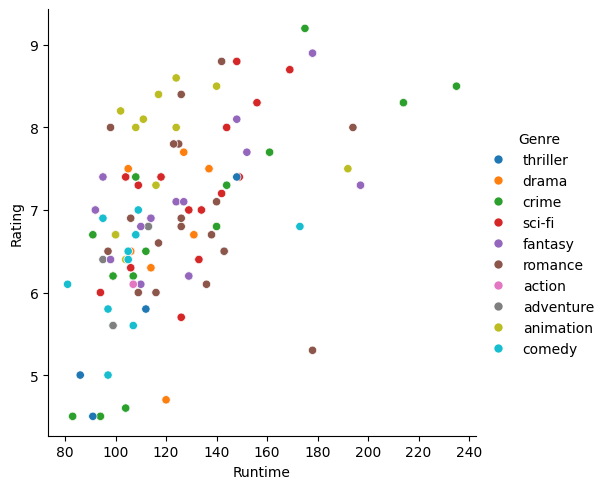

In [ ]:
# Genre , runtime, rating

sns.relplot(data=dfm,x="Runtime",y="Rating",hue="Genre")

**Observations**

- A positive relationship exists between runtime and rating.
- Higher-rated titles are generally concentrated in the runtime range of approximately 120–180 minutes.
- Several genres achieve ratings above 8.0 when runtime exceeds 130 minutes.
- Shorter titles (below 100 minutes) tend to have greater variation in ratings.
- Animation maintains strong ratings despite comparatively shorter runtimes.
- High-rated titles are present across multiple genres, indicating that genre alone does not determine success.

**Conclusion**
>Longer runtimes are generally associated with higher ratings, although well-rated titles exist across all genres and runtime ranges.

### Genre,Metascore,Rating

<Axes: xlabel='Metascore', ylabel='Rating'>

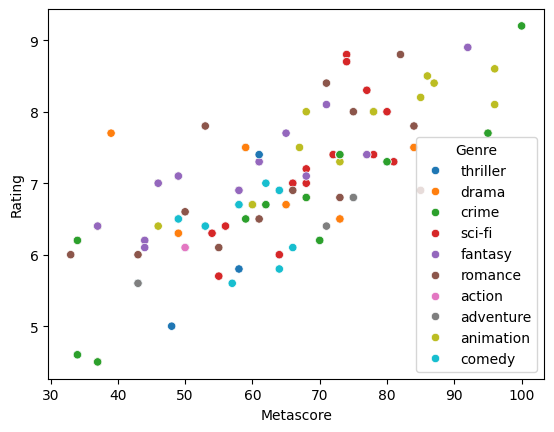

In [ ]:
# Genre , Metscore , Rating

sns.scatterplot(data=dfm,x="Metascore",y="Rating",hue="Genre")

**Insights**-# Do critic scores and audience ratings align across genres ?

**Observations**
- A strong positive relationship exists between Metascore and IMDb Rating.
- Titles with higher critic scores generally receive higher audience ratings.
- Most highly rated titles are concentrated in the Metascore range of 70–100.
- Lower Metascores are generally associated with lower audience ratings.
- The positive trend is visible across all genres.
- Very few titles receive high ratings despite low Metascores.

**Conclusion**
>Critic evaluations and audience ratings are strongly aligned, suggesting that highly reviewed titles tend to be appreciated by audiences as well.

### Certificate,Rating,Votes_K

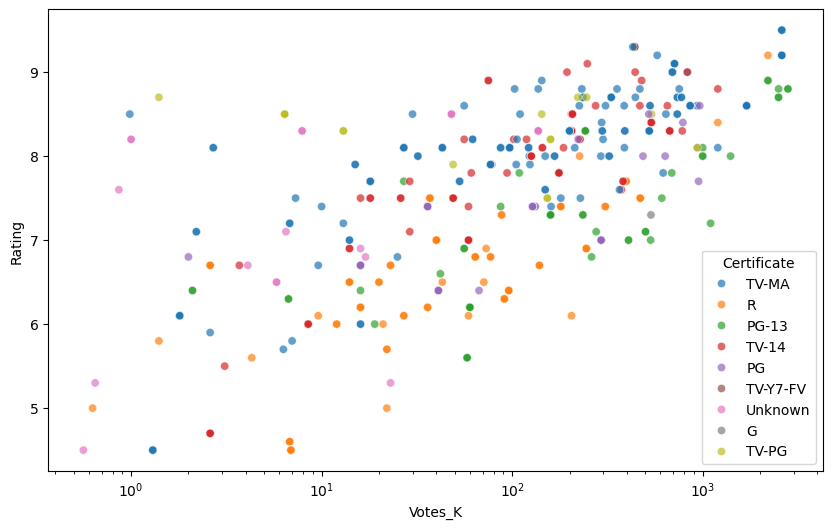

In [31]:
# sns.catplot(data=dfm,x="Votes_K",y="Rating",hue="Certificate")

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=dfm,
    x="Votes_K",
    y="Rating",
    hue="Certificate",
    alpha=0.7
)

plt.xscale("log")
plt.show()

**Observations**

- A moderate positive relationship exists between audience votes and IMDb ratings.
- Titles with higher ratings generally tend to receive more audience votes.
- Several highly voted titles have ratings above 8.0, indicating strong audience engagement.
- TV-MA titles are frequently observed in the higher-rating region of the plot.
- Lower-rated titles generally receive fewer votes, although some exceptions are present.
- Overall, audience engagement tends to increase as ratings increase.

**Conclusion**
>The analysis suggests a positive relationship between IMDb ratings and audience engagement. Titles with higher ratings generally attract more audience votes, while certificate categories such as TV-MA contain several highly rated and highly engaged titles.

### Genre,Year,Votes_K

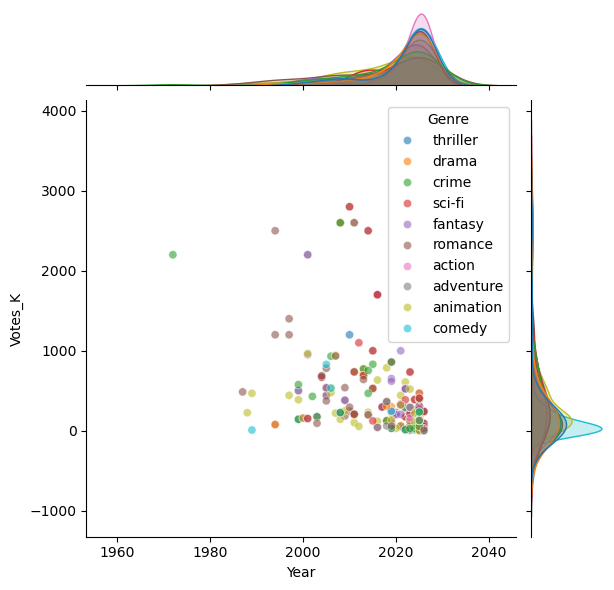

In [23]:
sns.jointplot(data=dfm,x="Year",y="Votes_K",hue="Genre",alpha=0.6,s=35)

**Observations**

- Most titles are concentrated between 2020 and 2026.
- Most movies receive less than 500K votes, while only a few have exceptionally high vote counts.
- Several outliers exceed 2000K votes, indicating highly popular titles.
- Vote counts vary across all genres, with no single genre dominating every year.

**Conclusion**
>Audience engagement is highly skewed. Most titles receive moderate vote counts, while a few blockbuster titles accumulate exceptionally high numbers of votes regardless of genre.


### Rating,Runtime,Metascore,Votes_K

<Axes: >

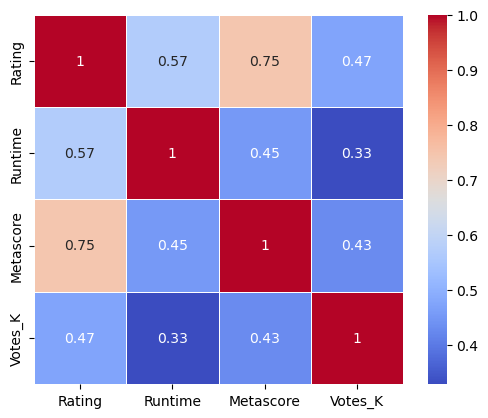

In [28]:
corr=dfm[["Rating","Runtime","Metascore","Votes_K"]].corr()
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    square=True
)

**Observations**

- Rating and Metascore show the strongest positive correlation.
- Runtime has a moderate positive relationship with Rating.
- Votes_K has a moderate positive relationship with both Rating and Metascore.
- Year is not included in this correlation analysis.

**Conclusion**
>The numerical variables generally exhibit positive relationships, with Rating and Metascore demonstrating the strongest association.

In [ ]:
# sns.violinplot(data=dfm,x="Rating",y="Votes_K",hue="Certificate")

### Genre , Metascore,Year

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'thriller'),
  Text(1, 0, 'drama'),
  Text(2, 0, 'crime'),
  Text(3, 0, 'sci-fi'),
  Text(4, 0, 'fantasy'),
  Text(5, 0, 'romance'),
  Text(6, 0, 'action'),
  Text(7, 0, 'adventure'),
  Text(8, 0, 'animation'),
  Text(9, 0, 'comedy')])

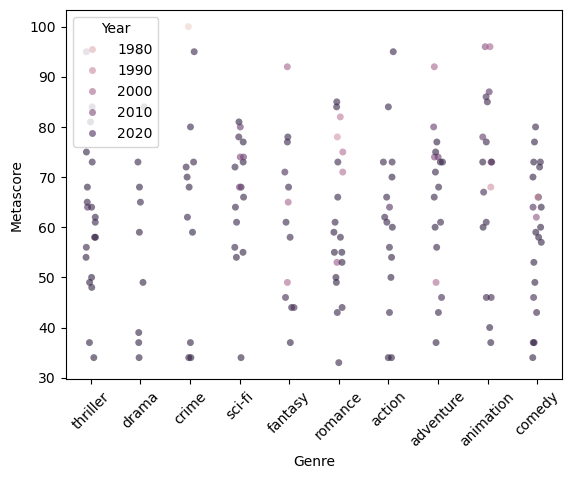

In [27]:
sns.stripplot(data=dfm,x="Genre",y="Metascore",hue="Year",jitter=True,alpha=0.6)
plt.xticks(rotation=45)

**Observations**

- Metascores range approximately from 33 to 100 across all genres.
- Animation and Adventure contain several high Metascore titles.
- Comedy and Romance exhibit a wider spread of critic scores.
- Most Metascores cluster between 55 and 80.

**Conclusion**
>Critic ratings vary within every genre, although Animation and Adventure appear to contain more highly reviewed titles.

✅ Catplot -- done

✅ Heatmap

✅ Swarmplot

✅ Stripplot

✅ FacetGrid -- done

✅ Pairplot

✅ Jointplot (though usually for 2 numerical variables)  --- done

✅ Violin Plot with hue

✅ Boxplot with hue

## Conclusion of Multivariate Analysis

- The multivariate analysis provided deeper insights into the relationships among genre, certificate, year, ratings, runtime, metascore, and audience votes.
- The analysis showed that audience engagement is influenced by a combination of factors rather than a single variable.
-  Genre and certificate together affect both IMDb ratings and vote counts, with categories such as TV-MA, Adventure, Animation, Fantasy, and Sci-fi generally showing higher ratings or audience engagement.
-   Correlation analysis also indicated positive relationships among ratings, metascores, runtime, and vote counts, suggesting that highly rated titles often receive greater audience attention and better critic reviews.
- Overall, the multivariate analysis highlighted how multiple features interact to influence the popularity and reception of titles, providing a more comprehensive understanding of the IMDb dataset.
